<a href="https://colab.research.google.com/github/machindie/Analisis-Peramalan-ARIMA/blob/main/ARIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

In [ ]:
df = pd.read_excel('data berita.xlsx')

In [ ]:
# Misalnya, dataset sudah berbentuk time series dengan index datetime
df = pd.read_csv('data.csv', parse_dates=['tanggal'], index_col='tanggal')

# Tampilkan ringkasan data
print(df.describe())
print(df.info())

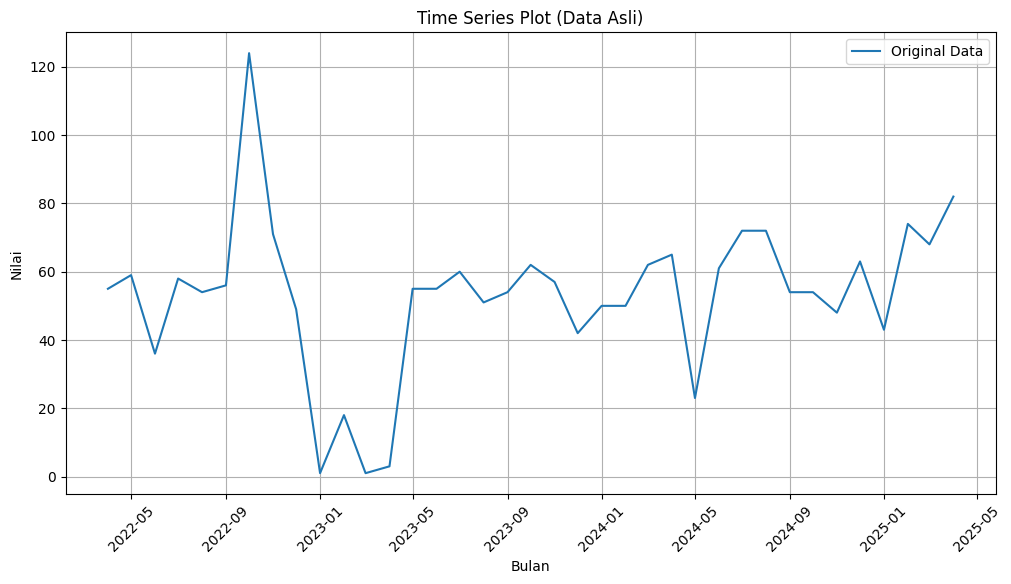

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df['Bulan'], df['Jumlah'], label='Original Data')
plt.title('Time Series Plot (Data Asli)')
plt.xlabel('Bulan')
plt.ylabel('Nilai')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
data = df['Jumlah_interpolated']
train_size = int(len(data) * 0.8)
train = data.iloc[:train_size]
test = data.iloc[train_size:]

In [ ]:
df

,Bulan,Jumlah,Jumlah_cleaned,Jumlah_interpolated
0,2022-04-01,55,55.0,55.0
1,2022-05-01,59,59.0,59.0
2,2022-06-01,36,36.0,36.0
3,2022-07-01,58,58.0,58.0
4,2022-08-01,54,54.0,54.0
5,2022-09-01,56,56.0,56.0
6,2022-10-01,124,NaN,63.5
7,2022-11-01,71,71.0,71.0
8,2022-12-01,49,49.0,49.0
9,2023-01-01,1,NaN,50.2


In [ ]:
train_size

29

In [ ]:
train

,Jumlah_interpolated
0,55.0
1,59.0
2,36.0
3,58.0
4,54.0
5,56.0
6,63.5
7,71.0
8,49.0
9,50.2


In [ ]:
test

,Jumlah_interpolated
29,54.0
30,54.0
31,48.0
32,63.0
33,43.0
34,74.0
35,68.0
36,68.0


In [ ]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train)
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
if adf_result[1] < 0.05:
    print("Data sudah stasioner.")
else:
    print("Data tidak stasioner, lakukan differencing.")

ADF Statistic: -3.3525226095329104
p-value: 0.012687855289209165
Data sudah stasioner.


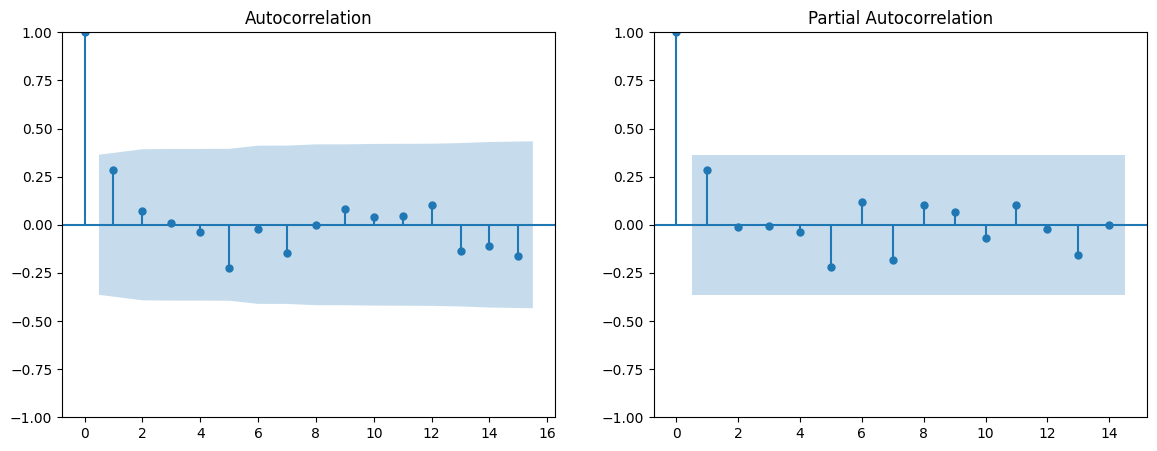

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(train.dropna(), lags=15, ax=ax[0])
plot_pacf(train.dropna(), lags=14, ax=ax[1])
plt.show()


Model ARIMA(1, 0, 1)
MAPE: 17.66%
AIC: 208.30
                                SARIMAX Results                                
Dep. Variable:     Jumlah_interpolated   No. Observations:                   29
Model:                  ARIMA(1, 0, 1)   Log Likelihood                -100.148
Date:                 Wed, 11 Jun 2025   AIC                            208.297
Time:                         04:45:22   BIC                            213.766
Sample:                              0   HQIC                           210.010
                                  - 29                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         56.8255      2.495     22.774      0.000      51.935      61.716
ar.L1          0.3895      0.871      0.447      0.655      -1.317       2.0

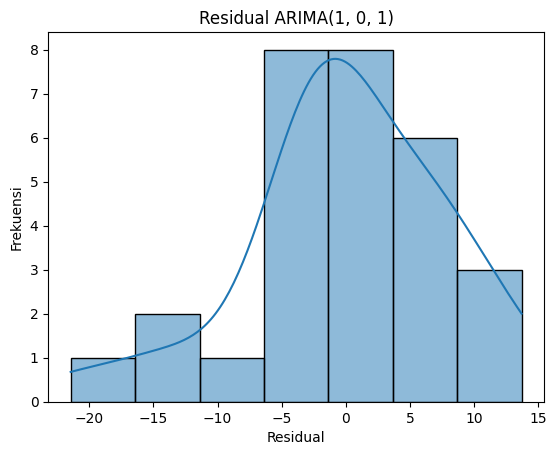


Model ARIMA(1, 0, 0)
MAPE: 17.41%
AIC: 206.31
                                SARIMAX Results                                
Dep. Variable:     Jumlah_interpolated   No. Observations:                   29
Model:                  ARIMA(1, 0, 0)   Log Likelihood                -100.156
Date:                 Wed, 11 Jun 2025   AIC                            206.313
Time:                         04:45:22   BIC                            210.415
Sample:                              0   HQIC                           207.597
                                  - 29                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         56.7827      2.401     23.653      0.000      52.078      61.488
ar.L1          0.3155      0.195      1.615      0.106      -0.067       0.6

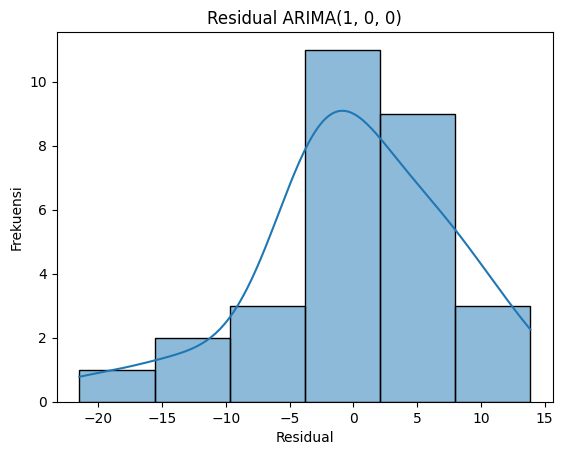


Model ARIMA(0, 0, 1)
MAPE: 16.53%
AIC: 206.63
                                SARIMAX Results                                
Dep. Variable:     Jumlah_interpolated   No. Observations:                   29
Model:                  ARIMA(0, 0, 1)   Log Likelihood                -100.315
Date:                 Wed, 11 Jun 2025   AIC                            206.629
Time:                         04:45:23   BIC                            210.731
Sample:                              0   HQIC                           207.914
                                  - 29                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         56.6399      2.072     27.333      0.000      52.578      60.701
ma.L1          0.2753      0.211      1.305      0.192      -0.138       0.6

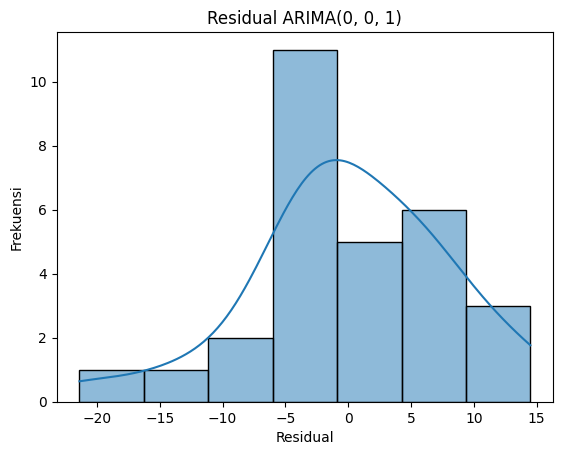


Model ARIMA(2, 0, 0)
MAPE: 17.66%
AIC: 208.30
                                SARIMAX Results                                
Dep. Variable:     Jumlah_interpolated   No. Observations:                   29
Model:                  ARIMA(2, 0, 0)   Log Likelihood                -100.148
Date:                 Wed, 11 Jun 2025   AIC                            208.296
Time:                         04:45:23   BIC                            213.766
Sample:                              0   HQIC                           210.009
                                  - 29                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         56.8258      2.497     22.761      0.000      51.933      61.719
ar.L1          0.3104      0.206      1.504      0.133      -0.094       0.7

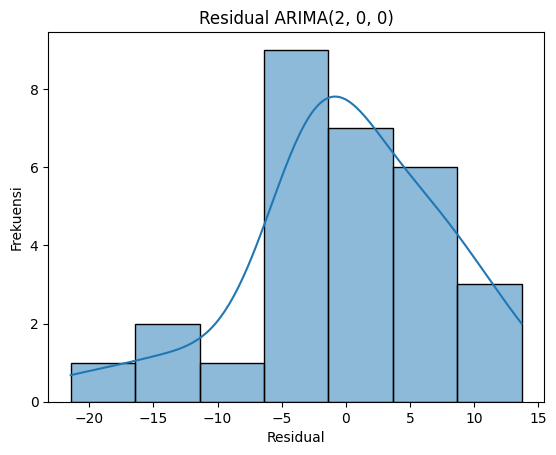


Model ARIMA(2, 0, 1)
MAPE: 17.65%
AIC: 210.30
                                SARIMAX Results                                
Dep. Variable:     Jumlah_interpolated   No. Observations:                   29
Model:                  ARIMA(2, 0, 1)   Log Likelihood                -100.148
Date:                 Wed, 11 Jun 2025   AIC                            210.296
Time:                         04:45:23   BIC                            217.133
Sample:                              0   HQIC                           212.438
                                  - 29                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         56.8245      2.494     22.785      0.000      51.937      61.712
ar.L1          0.2493     13.322      0.019      0.985     -25.861      26.3

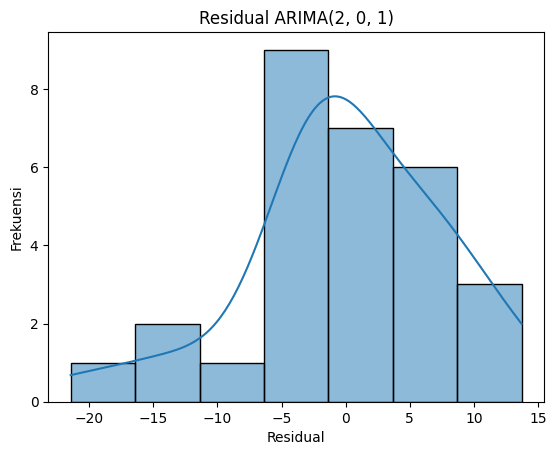


Hasil Evaluasi Model:
Model ARIMA(1, 0, 1): MAPE = 17.66%, AIC = 208.30
Model ARIMA(1, 0, 0): MAPE = 17.41%, AIC = 206.31
Model ARIMA(0, 0, 1): MAPE = 16.53%, AIC = 206.63
Model ARIMA(2, 0, 0): MAPE = 17.66%, AIC = 208.30
Model ARIMA(2, 0, 1): MAPE = 17.65%, AIC = 210.30


In [ ]:
# Import library yang dibutuhkan
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
import seaborn as sns

def evaluate_arima(order):
    print(f'\nModel ARIMA{order}')
    model = ARIMA(train, order=order)
    result = model.fit()

    # Forecast
    forecast = result.forecast(steps=len(test))

    # Hitung MAPE
    mape = mean_absolute_percentage_error(test, forecast) * 100
    print(f'MAPE: {mape:.2f}%')

    # Tampilkan AIC
    print(f'AIC: {result.aic:.2f}')

    # Uji Signifikansi
    print(result.summary())

    # Uji Autokorelasi Ljung-Box
    ljung = acorr_ljungbox(result.resid, lags=[10], return_df=True)
    print(f'\nUji Ljung-Box (Autokorelasi Residual): \n{ljung}')

    # Uji Normalitas Residual (Jarque-Bera)
    jb_test = jarque_bera(result.resid)
    print(f'\nUji Normalitas (Jarque-Bera) p-value: {jb_test[1]:.4f}')
    if jb_test[1] > 0.05:
        print('Residual terdistribusi normal (Jarque-Bera)')
    else:
        print('Residual tidak terdistribusi normal (Jarque-Bera)')

    # Plot Residual
    sns.histplot(result.resid, kde=True)
    plt.title(f'Residual ARIMA{order}')
    plt.xlabel('Residual')
    plt.ylabel('Frekuensi')
    plt.show()

    return mape, result.aic

# Model yang diuji
orders = [(1,0,1), (1,0,0), (0,0,1), (2,0,0), (2,0,1)]
results = {}

for order in orders:
    mape, aic = evaluate_arima(order)
    results[str(order)] = {'MAPE': mape, 'AIC': aic}

# Menampilkan hasil semua model
print("\nHasil Evaluasi Model:")
for order, metrics in results.items():
    print(f'Model ARIMA{order}: MAPE = {metrics["MAPE"]:.2f}%, AIC = {metrics["AIC"]:.2f}')

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import shapiro
import seaborn as sns

def evaluate_arima(order):
    print(f'\nModel ARIMA{order}')
    model = ARIMA(train, order=order)
    result = model.fit()

    # Forecast
    forecast = result.forecast(steps=6)

    # Hitung MAPE
    mape = mean_absolute_percentage_error(test, forecast) * 100
    print(f'MAPE: {mape:.2f}%')

    # Tampilkan AIC
    print(f'AIC: {result.aic:.2f}')

    # Uji Signifikansi
    print(result.summary())

    # Uji Autokorelasi Ljung-Box
    ljung = acorr_ljungbox(result.resid, lags=[10], return_df=True)
    print(f'\nUji Ljung-Box: \n{ljung}')

    # Uji Normalitas Residual (Shapiro-Wilk)
    shapiro_test = shapiro(result.resid)
    print(f'\nUji Normalitas (Shapiro-Wilk) p-value: {shapiro_test.pvalue:.4f}')
    if shapiro_test.pvalue > 0.05:
        print('Residual terdistribusi normal')
    else:
        print('Residual tidak terdistribusi normal')

    # Plot Residual
    sns.histplot(result.resid, kde=True)
    plt.title(f'Residual ARIMA{order}')
    plt.show()

    return mape, result.aic

# Model yang diuji
orders = [(1,0,1), (1,0,0), (0,0,1), (2,0,0), (2,0,1)]
results = {}

for order in orders:
    mape, aic = evaluate_arima(order)
    results[str(order)] = {'MAPE': mape, 'AIC': aic}


Model ARIMA(1, 0, 1)


ValueError: Found input variables with inconsistent numbers of samples: [8, 6]

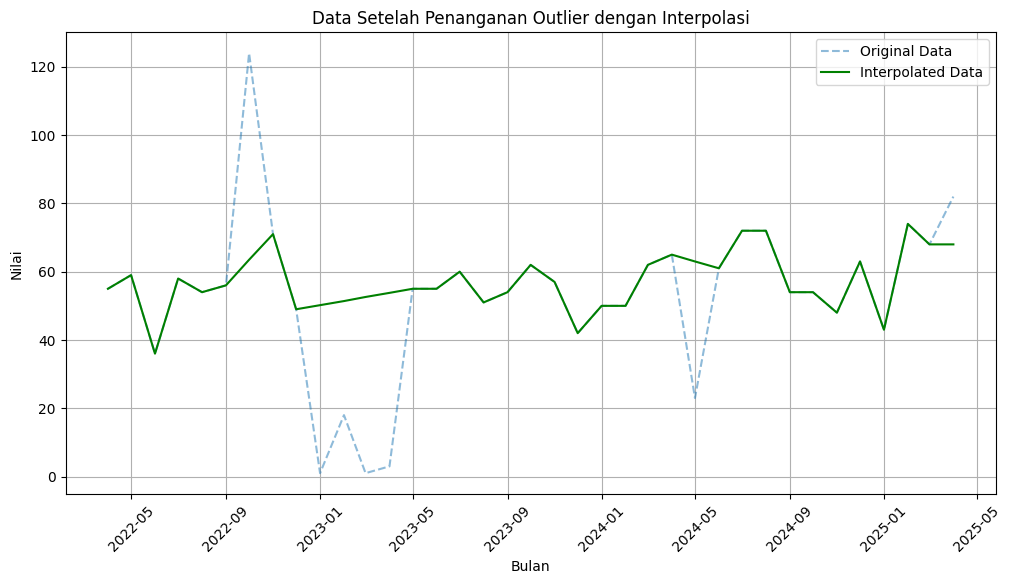

In [ ]:
Q1 = df['Jumlah'].quantile(0.25)
Q3 = df['Jumlah'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Tandai outlier
outliers = (df['Jumlah'] < lower_bound) | (df['Jumlah'] > upper_bound)

# Ganti outlier dengan NaN
df['Jumlah_cleaned'] = df['Jumlah']
df.loc[outliers, 'Jumlah_cleaned'] = np.nan

# Interpolasi untuk mengisi nilai yang hilang (outlier)
df['Jumlah_interpolated'] = df['Jumlah_cleaned'].interpolate(method='linear')

# Plot data setelah interpolasi
plt.figure(figsize=(12, 6))
plt.plot(df['Bulan'], df['Jumlah'], label='Original Data', linestyle='--', alpha=0.5)
plt.plot(df['Bulan'], df['Jumlah_interpolated'], label='Interpolated Data', color='green')
plt.title('Data Setelah Penanganan Outlier dengan Interpolasi')
plt.xlabel('Bulan')
plt.ylabel('Nilai')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()

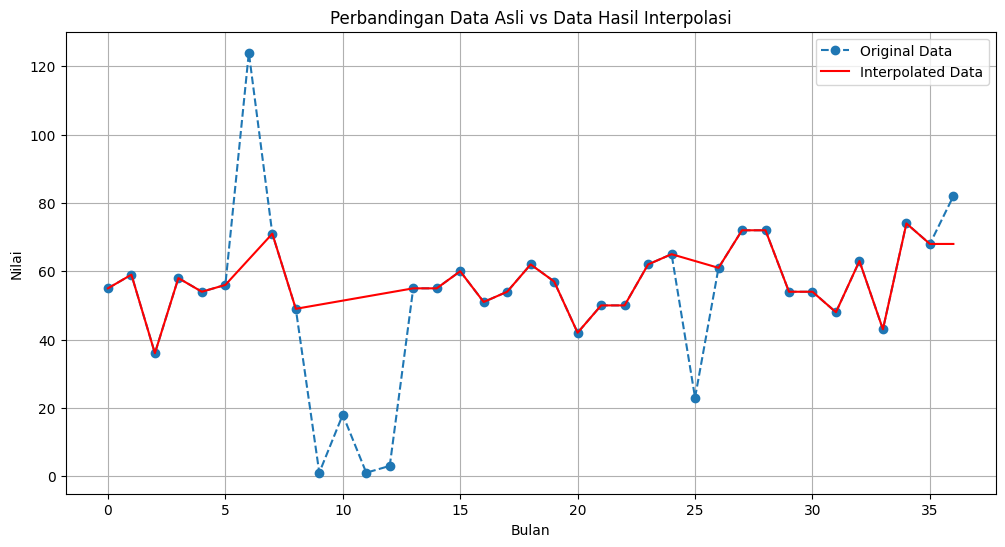

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel('data berita.xlsx')

# Contoh data kamu
data = df['Jumlah']  # Ubah sesuai nama kolom kamu

# 1. Deteksi Outlier Menggunakan IQR
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

# Batas deteksi outlier
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 2. Tandai outlier sebagai NaN
data_clean = data.copy()
data_clean[(data < lower_bound) | (data > upper_bound)] = np.nan

# 3. Interpolasi Linear untuk Mengganti Outlier
data_interpolated = data_clean.interpolate(method='linear')

# 4. Visualisasi Hasil
plt.figure(figsize=(12,6))
plt.plot(data.index, data, label='Original Data', linestyle='--', marker='o')
plt.plot(data_interpolated.index, data_interpolated, label='Interpolated Data', color='red')
plt.xlabel('Bulan')
plt.ylabel('Nilai')
plt.title('Perbandingan Data Asli vs Data Hasil Interpolasi')
plt.legend()
plt.grid(True)
plt.show()

# Jika mau disimpan ke DataFrame
df['nilai_interpolated'] = data_interpolated


In [ ]:
df

,Bulan,Jumlah,nilai_interpolated
0,2022-04-01,55,55.0
1,2022-05-01,59,59.0
2,2022-06-01,36,36.0
3,2022-07-01,58,58.0
4,2022-08-01,54,54.0
5,2022-09-01,56,56.0
6,2022-10-01,124,63.5
7,2022-11-01,71,71.0
8,2022-12-01,49,49.0
9,2023-01-01,1,50.2


ARIMA(2, 0, 1) MAPE: 0.1765


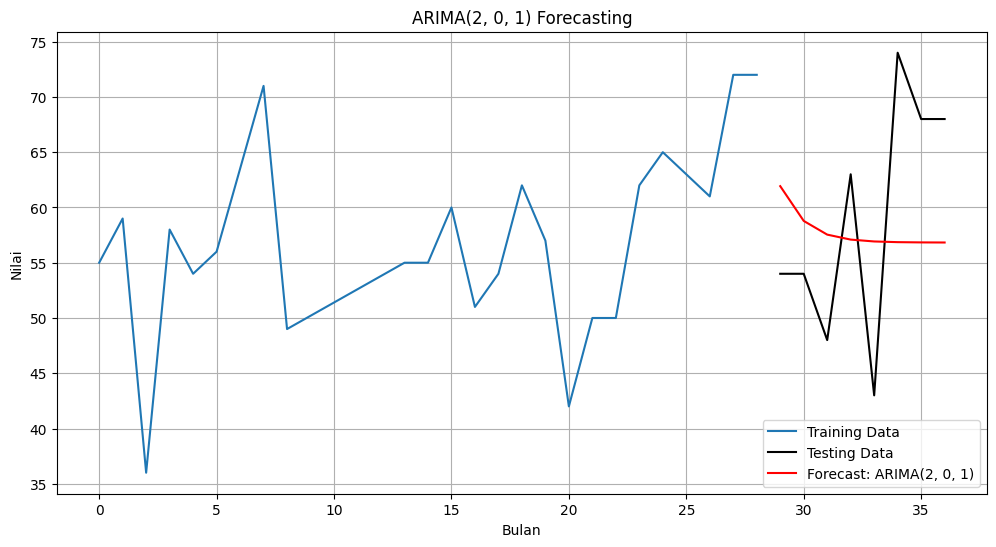

ARIMA(1, 0, 1) MAPE: 0.1766


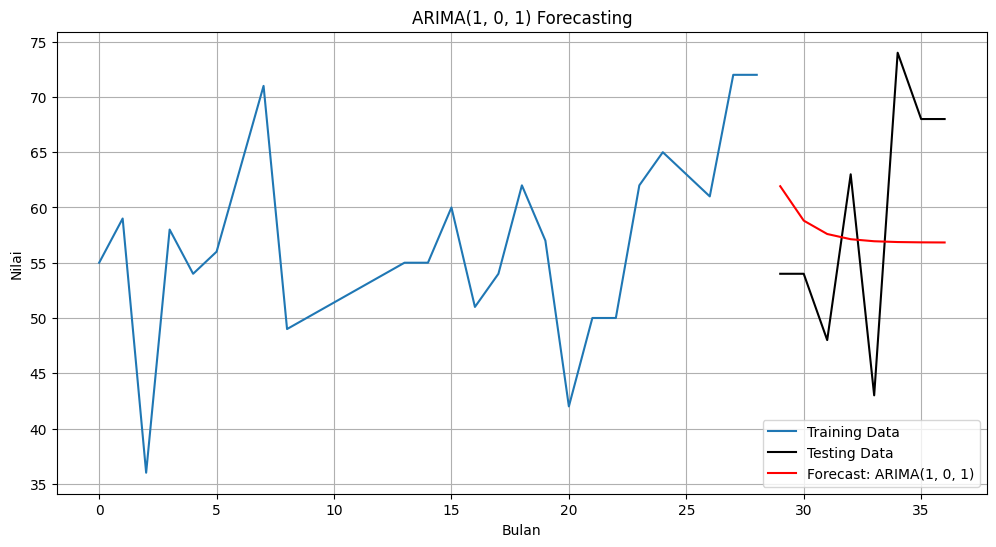

ARIMA(1, 0, 0) MAPE: 0.1741


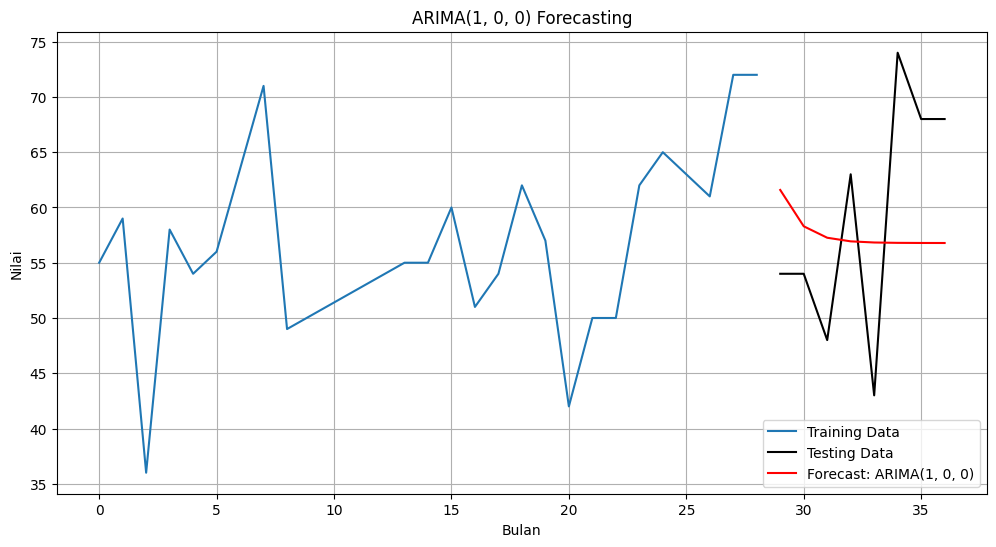

ARIMA(2, 0, 0) MAPE: 0.1766


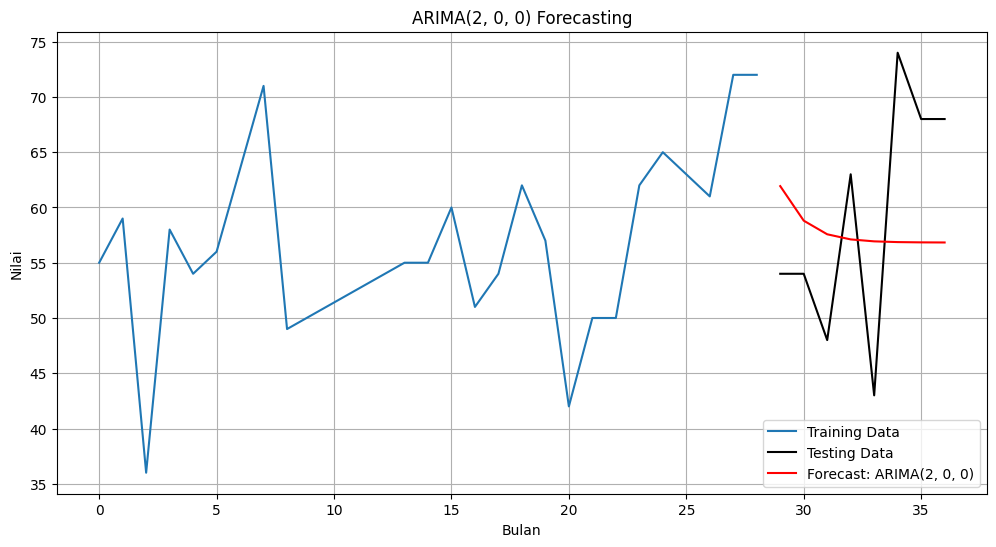

ARIMA(0, 0, 1) MAPE: 0.1653


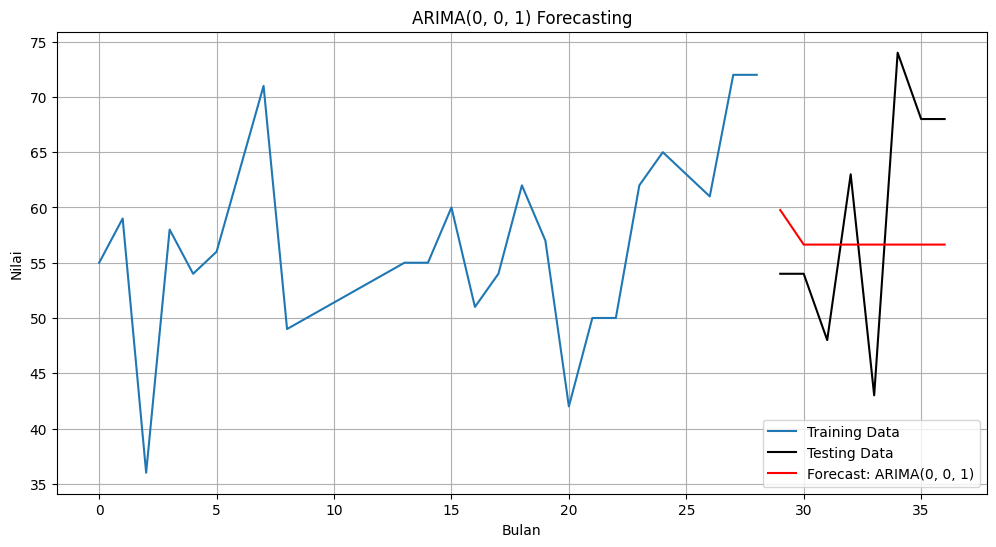


Ringkasan Hasil MAPE:
ARIMA(2, 0, 1): MAPE = 17.6473%
ARIMA(1, 0, 1): MAPE = 17.6622%
ARIMA(1, 0, 0): MAPE = 17.4145%
ARIMA(2, 0, 0): MAPE = 17.6586%
ARIMA(0, 0, 1): MAPE = 16.5325%


In [ ]:
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt

# Gunakan data hasil interpolasi (tanpa outlier)
data = df['nilai_interpolated']

# Pastikan data sudah dipecah jadi training dan testing
train_size = int(len(data) * 0.8)
train = data.iloc[:train_size]
test = data.iloc[train_size:]

# Daftar model ARIMA yang akan dicoba
arima_orders = [
    (2, 0, 1),
    (1, 0, 1),
    (1, 0, 0),
    (2, 0, 0),
    (0, 0, 1)
]

# Simpan hasil evaluasi
results = {}

# Loop untuk membangun model, forecasting, dan hitung MAPE
for order in arima_orders:
    try:
        model = ARIMA(train, order=order).fit()
        forecast = model.forecast(steps=len(test))
        mape = mean_absolute_percentage_error(test, forecast)

        results[f'ARIMA{order}'] = {
            'model': model,
            'forecast': forecast,
            'mape': mape
        }

        print(f"ARIMA{order} MAPE: {mape:.4f}")

        # Plot untuk masing-masing model
        plt.figure(figsize=(12, 6))
        plt.plot(train.index, train, label='Training Data')
        plt.plot(test.index, test, label='Testing Data', color='black')
        plt.plot(test.index, forecast, label=f'Forecast: ARIMA{order}', color='red')
        plt.xlabel('Bulan')
        plt.ylabel('Nilai')
        plt.title(f'ARIMA{order} Forecasting')
        plt.legend()
        plt.grid(True)
        plt.show()

    except Exception as e:
        print(f"Gagal membangun ARIMA{order} - Error: {e}")

# Cetak hasil model dan MAPE
print("\nRingkasan Hasil MAPE:")
for model_name, result in results.items():
    print(f"{model_name}: MAPE = {result['mape']:.4%}")
